# Assignment 3, Part 2 — Autoencoders, SVMs, and clustering

**Praveen, roll m26csa003. Split seed 26003.**

This notebook is Question 3 and Question 4. It loads the saved split, the autoencoder logs, and the SVM logs from disk. It does not read variables from `Assignment_3_Part_1.ipynb`. The classifier and the 160-dimensional features come from the Question 1 matched CNN checkpoint that was selected by validation accuracy (seed 26003). That checkpoint is a file, first introduced in Question 1a.

The training and fitting code is imported from `src/` so it stays the code that wrote the logs. `RECOMPUTE = False` skips a repeat of that work.

## 1. Objectives

**Question 3.** Train three convolutional autoencoders that differ only in bottleneck width. If reconstruction error were the only criterion, choose one on the validation set. Train a denoiser for Gaussian noise and compare a frozen CNN on corrupted images and on reconstructions. Without fine-tuning the encoders, measure how much class information a linear probe can read, and compare that with reconstruction quality.

**Question 4.** Freeze one representation. Sweep at least five values of \(C\) across at least three orders of magnitude, and at least three kernels including RBF. Select on validation, then evaluate once on the test set. Inspect three hard class pairs, and cluster the same representation without labels during fitting.

## 2. Imports, paths, and the recompute switch

In [1]:
from pathlib import Path
import sys

HERE = Path.cwd().resolve()
CANDIDATES = [HERE, *HERE.parents, Path("/scratch/m26csa003/ML_assignment_3")]
ROOT = next(path for path in CANDIDATES if (path / "src" / "common" / "data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Saved logs are the reported results. Set this to True only on a GPU node
# when you intend to repeat training. The training entry points are the same
# functions the batch jobs called.
RECOMPUTE = False

import os
os.environ.setdefault("PYTHONNOUSERSITE", "1")

from IPython.display import display, Image, Markdown, HTML

def show_rows(rows, columns=None, digits=4):
    """Render a list of dicts as an HTML table."""
    if not rows:
        display(Markdown("*No rows.*"))
        return
    columns = list(columns or rows[0].keys())

    def cell(value):
        if isinstance(value, float):
            return f"{value:.{digits}f}"
        return "" if value is None else str(value)

    head = "".join(f"<th style='text-align:left;padding:4px 8px'>{name}</th>" for name in columns)
    body = []
    for row in rows:
        body.append("<tr>" + "".join(
            f"<td style='padding:4px 8px'>{cell(row.get(name, ''))}</td>" for name in columns
        ) + "</tr>")
    display(HTML(
        "<table style='border-collapse:collapse;font-size:13px'>"
        f"<thead><tr>{head}</tr></thead><tbody>{''.join(body)}</tbody></table>"
    ))

def show_figure(relative, width=720):
    path = ROOT / relative
    if not path.exists():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))

print("Project root:", ROOT)
print("RECOMPUTE =", RECOMPUTE)

Project root: /scratch/m26csa003/ML_assignment_3
RECOMPUTE = False


## 3. Split check

This cell reloads the same split file Question 1 used and checks that a fresh draw from seed 26003 still matches it. Validation and test images are not used to recompute the channel statistics.

In [2]:
import json
from src.common.data import prepare_dataset, SEED

prepared = prepare_dataset(ROOT)
report = prepared["report"]
assert report["train_size"] == 45000
assert report["val_size"] == 5000
assert report["overlap"] == 0
assert report["train_counts"] == [4500] * 10
assert int(SEED) == 26003
print("split status:", report["split_status"])
print("train index sha256:", report["train_idx_sha256"])
show_rows([{
    "train": report["train_size"],
    "validation": report["val_size"],
    "test": report["test_size"],
    "overlap": report["overlap"],
}])

Files already downloaded and verified


Files already downloaded and verified


split status: reloaded
train index sha256: 97af65b491226b292df93e2a67fa52812257f3db3c0f045799d4eb675c70f04a


train,validation,test,overlap
45000,5000,10000,0


## 4. Question 3 — three bottleneck widths

The plan is `configs/q3_plan.json`, written before training. The convolutions are identical. Only `to_code.weight`, `to_code.bias`, and `from_code.weight` change with the bottleneck. Images stay in \([0, 1]\). The loss is pixel mean squared error. Weight decay is 0. The learning rate is chosen by a 4-epoch probe on the middle bottleneck (128): lowest validation MSE wins, and the smaller learning rate wins a tie.

The checkpoint is the lowest validation MSE, earliest epoch on a tie. The bottleneck is chosen the same way. Test reconstruction error of the selected model is written only after that choice.

In [3]:
import csv
import inspect
from src.q3.models import ConvAutoencoder
from src.q3.pipeline import assert_architecture
from src.q3.figures import write_q3_figures

plan = json.loads((ROOT / "configs" / "q3_plan.json").read_text())
print("written before training:", plan["written_before_training"])
assert_architecture(plan)
print(plan["architecture"])
display(Markdown("```python\n" + inspect.getsource(ConvAutoencoder) + "```"))

chosen_lr = json.loads((ROOT / "results" / "q3" / "chosen_lr.json").read_text())
print("probe rule:", chosen_lr["rule"])
show_rows([
    {"learning_rate": row["lr"], "best_validation_mse": row["best_val_mse"]}
    for row in chosen_lr["rows"]
])
print("chosen learning rate:", chosen_lr["chosen_lr"])

selection = json.loads((ROOT / "results" / "q3" / "q3a_selection.json").read_text())
print("selection rule:", selection["rule"])
print("chosen bottleneck:", selection["chosen_bottleneck"])
show_rows(selection["rows"])
test_mse = json.loads((ROOT / "results" / "q3" / "q3a_test_mse.json").read_text())
print("selected test MSE:", test_mse["test_mse"], "PSNR:", test_mse["test_psnr"])
if int(test_mse["bottleneck"]) != int(selection["chosen_bottleneck"]):
    raise AssertionError("Test MSE file is not the selected bottleneck.")

written before training: 2026-11-10T17:48:52+05:30
Three 3x3 convolutions, 32 then 64 then 128 channels, ReLU and 2x2 max-pool after each, linear map to the bottleneck, linear map back to 128x4x4, then three stride-2 transposed convolutions back to 32x32 with a sigmoid. No batch norm. The code has no activation. to_code.weight, to_code.bias and from_code.weight change with the bottleneck. from_code.bias has one entry per decoded unit, so it stays the same width.


```python
class ConvAutoencoder(nn.Module):
    """Encode a 32x32 image to a vector, then decode it back to 32x32.

    The convolutions are identical for every bottleneck. Only the two linear
    maps that enter and leave the code change width. There is no batch norm,
    so a lower reconstruction error cannot be blamed on a different normaliser.
    The code itself has no ReLU: the width of that vector is the capacity.
    """

    def __init__(self, bottleneck):
        super().__init__()
        self.bottleneck = int(bottleneck)
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        flat = 128 * 4 * 4
        self.to_code = nn.Linear(flat, self.bottleneck)
        self.from_code = nn.Linear(self.bottleneck, flat)
        # Kernel 2 and stride 2 invert the three pools: 4 -> 8 -> 16 -> 32.
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=2, stride=2),
            nn.Sigmoid(),
        )

    def encode(self, images):
        features = self.encoder_conv(images)
        return self.to_code(features.flatten(1))

    def decode(self, code):
        flat = self.from_code(code)
        spatial = flat.reshape(code.shape[0], 128, 4, 4)
        return self.decoder_conv(spatial)

    def forward(self, images):
        return self.decode(self.encode(images))
```

probe rule: Lowest best validation MSE on the middle bottleneck wins. The smaller learning rate wins a tie. A non-finite probe scores infinity.


learning_rate,best_validation_mse
0.0003,0.0134
0.0010,0.0100
0.0030,0.0094


chosen learning rate: 0.003
selection rule: If reconstruction error were the only criterion, choose the clean autoencoder with the lowest best validation MSE. A tie keeps the smaller bottleneck. The test set is not used for this choice.
chosen bottleneck: 512


bottleneck,parameters,best_val_mse,best_epoch,checkpoint
32,267843,0.0115,20,/scratch/m26csa003/ML_assignment_3/results/q3/checkpoints/clean_b32_seed26003.pt
128,661155,0.0056,20,/scratch/m26csa003/ML_assignment_3/results/q3/checkpoints/clean_b128_seed26003.pt
512,2234403,0.0048,20,/scratch/m26csa003/ML_assignment_3/results/q3/checkpoints/clean_b512_seed26003.pt


selected test MSE: 0.004834359914064407 PSNR: 23.156610198626957


## 5. Question 3b and 3c — denoising and linear probes

Corruption is additive Gaussian noise with standard deviation 0.25 on images in \([0, 1]\), then clipped. One frozen noisy validation set and one frozen noisy test set were drawn before training. The denoiser has the bottleneck selected above. Its inputs are noisy and its targets are clean. Class labels are not used.

The classifier is the Question 1a matched CNN with the highest validation accuracy. Ties would keep the lower seed. It is frozen. Reconstructions and noisy images are normalised with the Question 1 training mean and standard deviation before they are classified, which is the transform that CNN was trained with.

The linear probe is multinomial logistic regression on the frozen code. \(C\) is chosen on the validation codes. Encoders are not fine-tuned.

condition,test_accuracy,pixel_mse,psnr
clean,0.7612,0.0000,
corrupted,0.1670,0.0484,13.15288905
clean_ae_of_corrupted,0.3345,0.0097,20.11652355
denoising_ae_of_corrupted,0.3296,0.0076,21.20741541


role,bottleneck,val_mse,test_mse,probe_C,probe_val_accuracy,probe_test_accuracy
clean,32,0.01152495,0.01160273,0.01000000,0.36680000,0.36400000
clean,128,0.00557111,0.00562695,100.00000000,0.44480000,0.44380000
clean,512,0.00478872,0.00483436,1.00000000,0.55040000,0.54530000
denoising,512,0.00751155,,1.00000000,0.54220000,0.53920000


denoiser training seconds: 79.4, best epoch 20


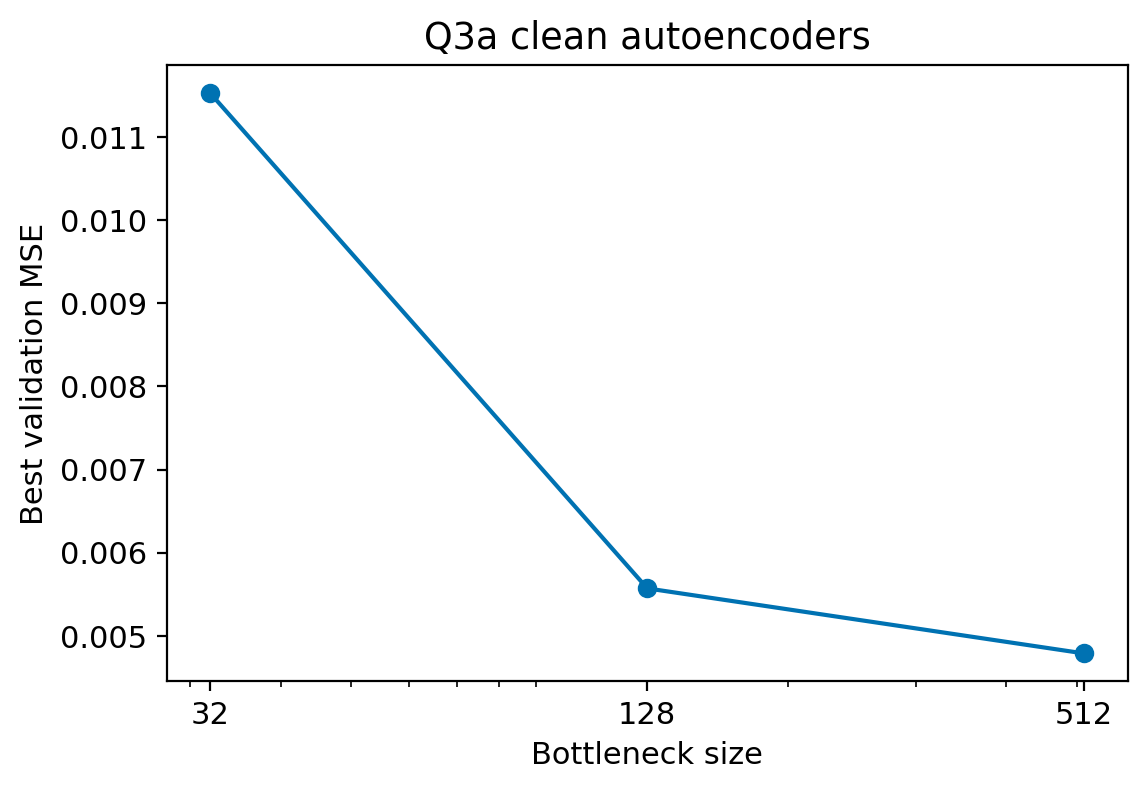

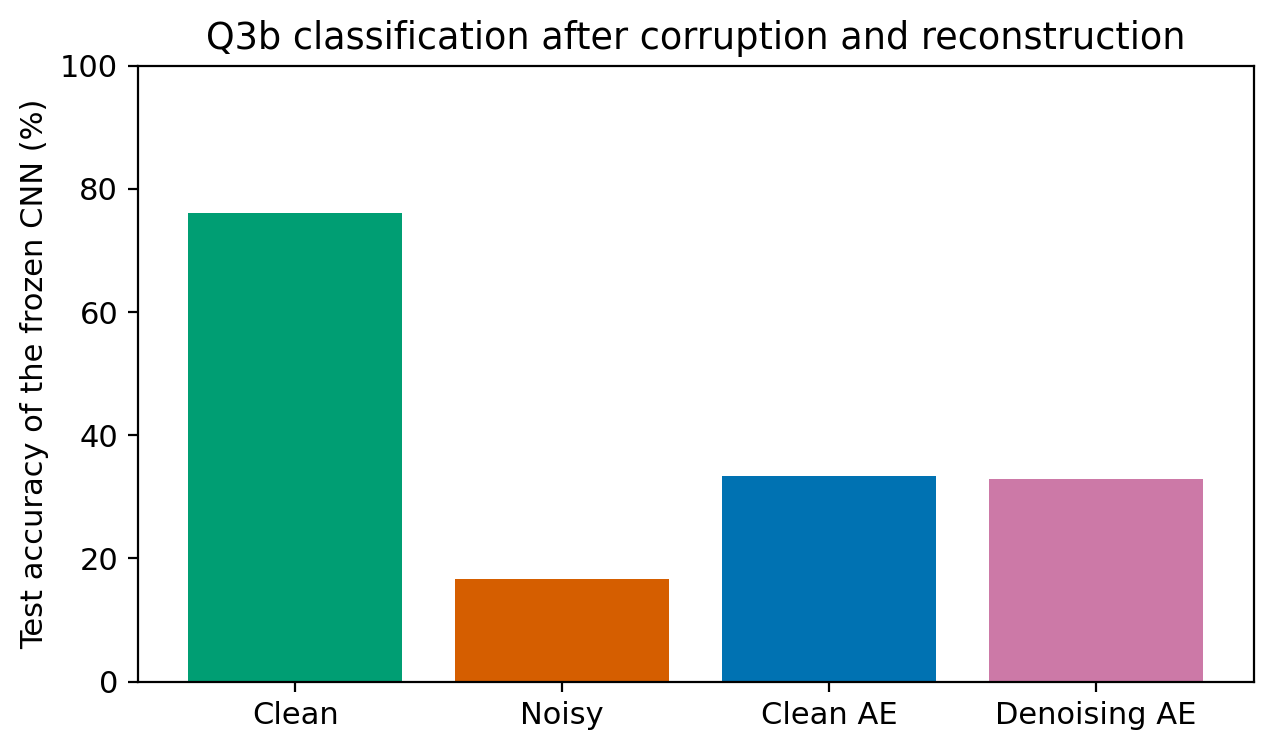

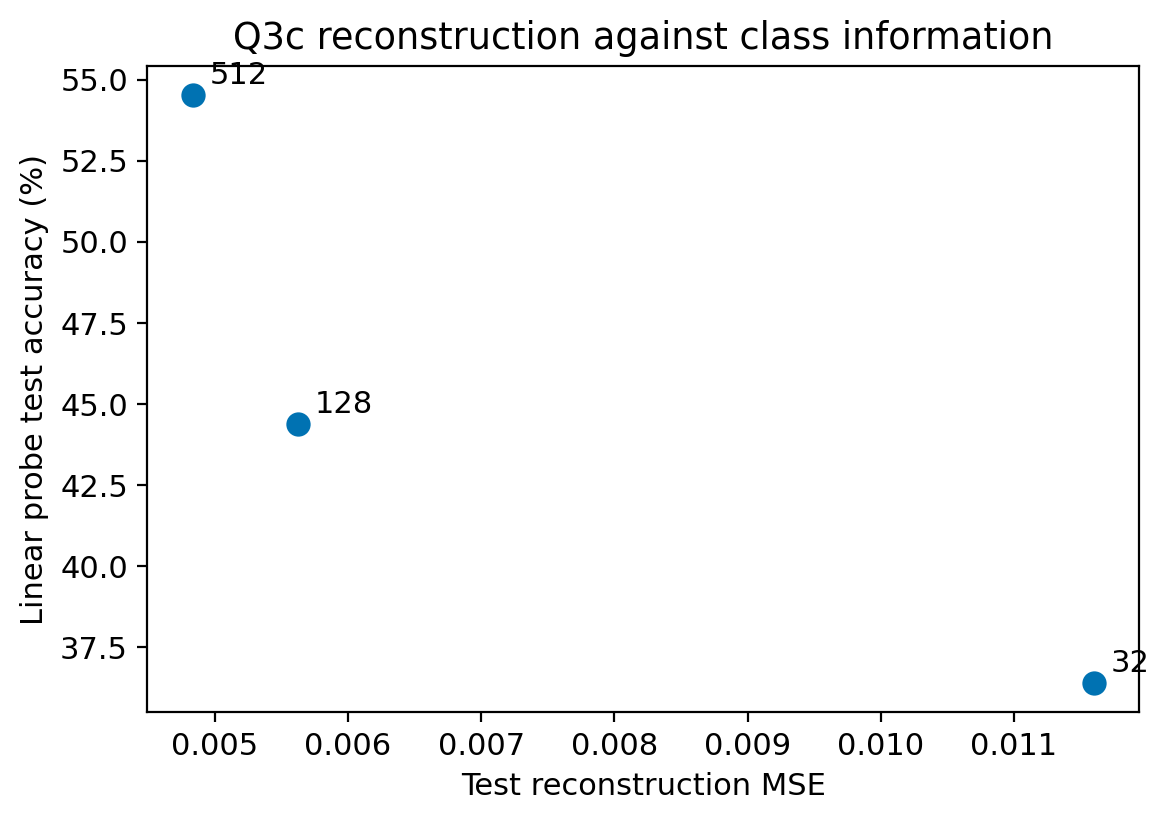

In [4]:
write_q3_figures(ROOT)
with (ROOT / "results" / "q3" / "q3b_classification.csv").open() as handle:
    class_rows = list(csv.DictReader(handle))
show_rows([
    {
        "condition": row["condition"],
        "test_accuracy": float(row["test_accuracy"]),
        "pixel_mse": float(row["pixel_mse_vs_clean"]),
        "psnr": row["psnr_vs_clean"],
    }
    for row in class_rows
])
with (ROOT / "results" / "q3" / "q3c_representation.csv").open() as handle:
    rep_rows = list(csv.DictReader(handle))
show_rows(rep_rows)
denoise = json.loads((ROOT / "results" / "q3" / "denoise" / "ae_b512_seed26003.json").read_text())
print(f"denoiser training seconds: {denoise['seconds']:.1f}, best epoch {denoise['best_epoch']}")
for name in (
    "figures/q3/q3a_val_mse.png",
    "figures/q3/q3b_classification.png",
    "figures/q3/q3c_mse_vs_probe.png",
):
    show_figure(name)

### Reading of Question 3

Validation MSE falls with the bottleneck: 0.01152 at width 32, 0.00557 at 128, and 0.00479 at 512. The written rule selects 512. Its test MSE is 0.00483 (PSNR 23.16). All three clean models were still best on epoch 20, the last epoch of the budget, so a longer run could lower every curve. The order is already clear.

The frozen CNN scores 0.761 on clean test images and 0.167 on the noisy images. The clean autoencoder's reconstruction of those noisy images scores 0.334. The denoiser scores 0.330 and has the better PSNR (21.21 against 20.12). Better pixels did not restore the classifier. Both reconstructions help relative to the raw noisy image and leave most of the gap to the clean image.

Probe test accuracy is 0.364, 0.444 and 0.545 as the code widens. Reconstruction and class information move in the same direction. Most of the MSE drop is from 32 to 128. The probe keeps rising from 128 to 512, where the MSE drop is small. Some logistic fits hit the 400-iteration limit, so an individual \(C\) can be slightly short of its optimum. The gaps between bottlenecks are larger than that.

## 6. Question 4 — a frozen code, then an SVM

The representation is the 160-dimensional vector after global average pooling in the Question 1a matched CNN, before the linear head. The checkpoint is seed 26003, chosen because it had the highest validation accuracy among the three Question 1 seeds. The network is not updated.

The SVM training subset is 200 images from each class inside the 45,000 training rows, drawn with `Generator(26003)` and saved before any fit (`splits/q4_svm_subset_seed26003.npy`). Every kernel and every \(C\) uses that file. Features are standardised with the mean and standard deviation of those 2,000 rows only.

Kernels are linear, polynomial (degree 3, `coef0` 1, `gamma='scale'`), and RBF (`gamma='scale'`). Degree and gamma are not searched. \(C\) is 0.01, 0.1, 1, 10 and 100. The highest validation accuracy wins. A tie keeps the smaller support-vector fraction, then the smaller \(C\), then the kernel name in alphabetical order. The winner is evaluated once on the official test set.

written before any fit: 2026-11-10T17:48:52+05:30
subset size: 2000 per class: 200
C values: [0.01, 0.1, 1.0, 10.0, 100.0]
kernels: ['linear', 'poly', 'rbf']


Files already downloaded and verified


Files already downloaded and verified


kernel,C,train,validation,support_fraction
linear,0.0100,0.9095,0.7296,0.6780
linear,0.1000,0.9745,0.7190,0.5395
linear,1.0000,0.9980,0.7086,0.5070
linear,10.0000,1.0000,0.7096,0.5030
linear,100.0000,1.0000,0.7096,0.5030
poly,0.0100,0.7145,0.6402,0.9355
poly,0.1000,0.9170,0.7254,0.7610
poly,1.0000,0.9990,0.7340,0.6855
poly,10.0000,1.0000,0.7256,0.6860
poly,100.0000,1.0000,0.7256,0.6860


selected: poly C = 1.0 validation = 0.734
single test accuracy: 0.7235


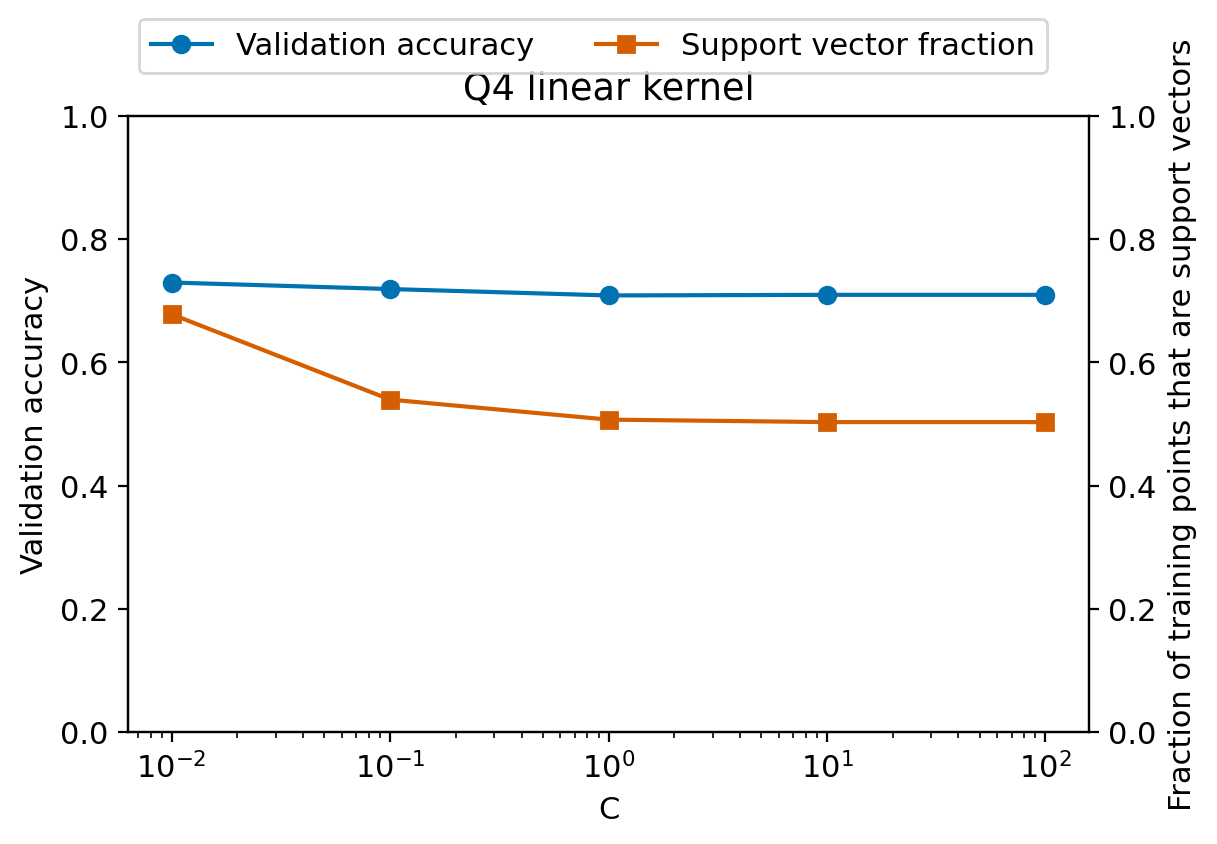

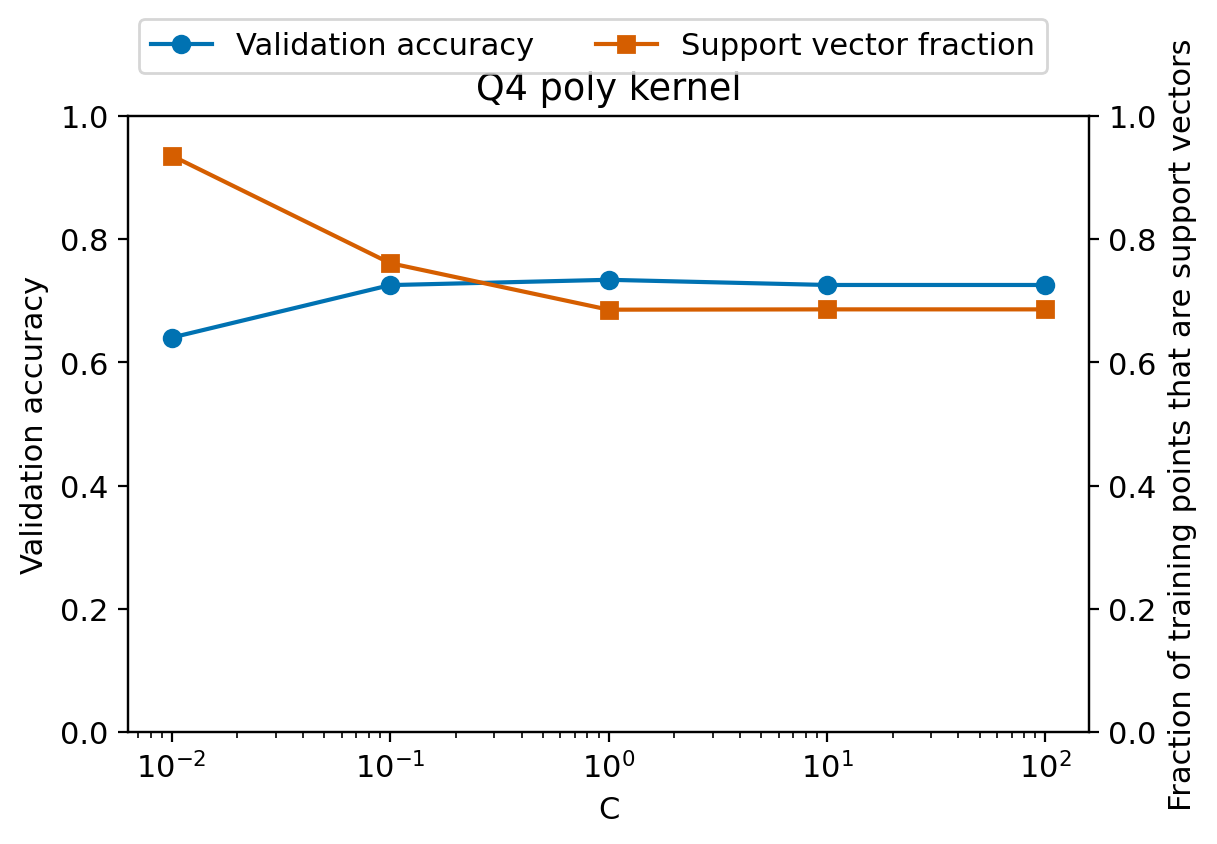

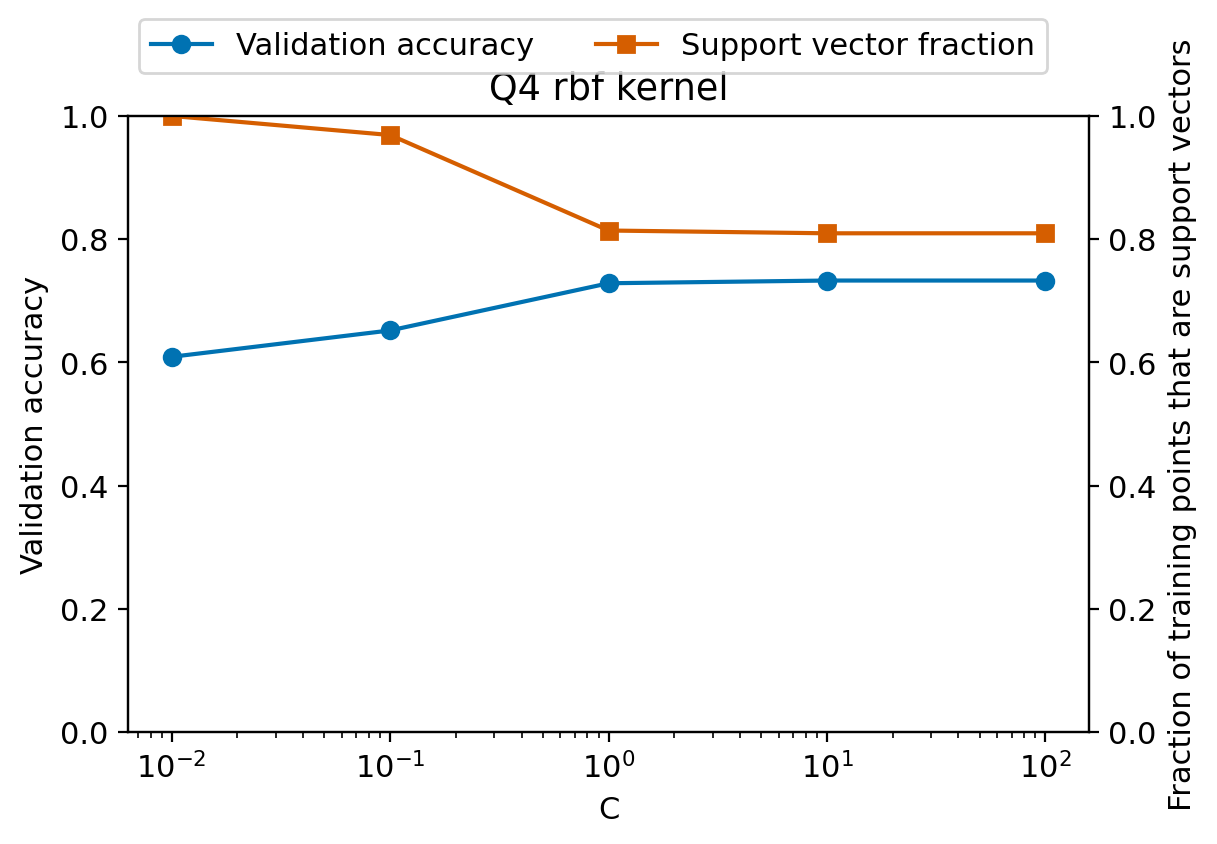

In [5]:
from src.q4.figures import write_q4_figures

q4 = json.loads((ROOT / "configs" / "q4_plan.json").read_text())
print("written before any fit:", q4["written_before_any_fit"])
print("subset size:", q4["subset_size"], "per class:", q4["subset_per_class"])
print("C values:", q4["C_values"])
print("kernels:", q4["kernels"])
subset = __import__("numpy").load(ROOT / "splits" / "q4_svm_subset_seed26003.npy")
if subset.shape != (2000,):
    raise AssertionError(f"Subset length is {subset.shape}, the plan says 2000.")

write_q4_figures(ROOT)
with (ROOT / "results" / "q4" / "svm_sweep.csv").open() as handle:
    sweep = list(csv.DictReader(handle))
show_rows([
    {
        "kernel": row["kernel"],
        "C": float(row["C"]),
        "train": float(row["train_accuracy"]),
        "validation": float(row["val_accuracy"]),
        "support_fraction": float(row["support_fraction"]),
    }
    for row in sweep
])
selected = json.loads((ROOT / "results" / "q4" / "svm_selection.json").read_text())
tested = json.loads((ROOT / "results" / "q4" / "svm_test.json").read_text())
print("selected:", selected["kernel"], "C =", selected["C"], "validation =", selected["val_accuracy"])
print("single test accuracy:", tested["test_accuracy"])
# The selected row must be the unique validation maximum in the sweep.
best_val = max(float(row["val_accuracy"]) for row in sweep)
if abs(best_val - float(selected["val_accuracy"])) > 1e-6:
    raise AssertionError("Selection file is not the best validation row.")
for kernel in ("linear", "poly", "rbf"):
    show_figure(f"figures/q4/q4_{kernel}.png")

## 7. Question 4b — three hard pairs

After the single test evaluation, unordered class pairs are ranked by the sum of the two off-diagonal confusion counts. The three largest are kept. A tie would keep the smaller class index. This uses test labels to choose which pairs to draw, which the question asks for, and it does not change \(C\) or the kernel.

For each pair the score is that column of the one-versus-one decision function. The figure shows up to eight training support vectors of that binary problem and eight test images of the two classes with the smallest absolute score.

pair,test_confusions,pair_images,error_rate,support_vectors,closest_test_score,closest_correct
cat / dog,358,2000,0.1790,222,0.0014,False
bird / deer,178,2000,0.0890,171,-0.0001,False
airplane / ship,146,2000,0.0730,139,-0.0006,False


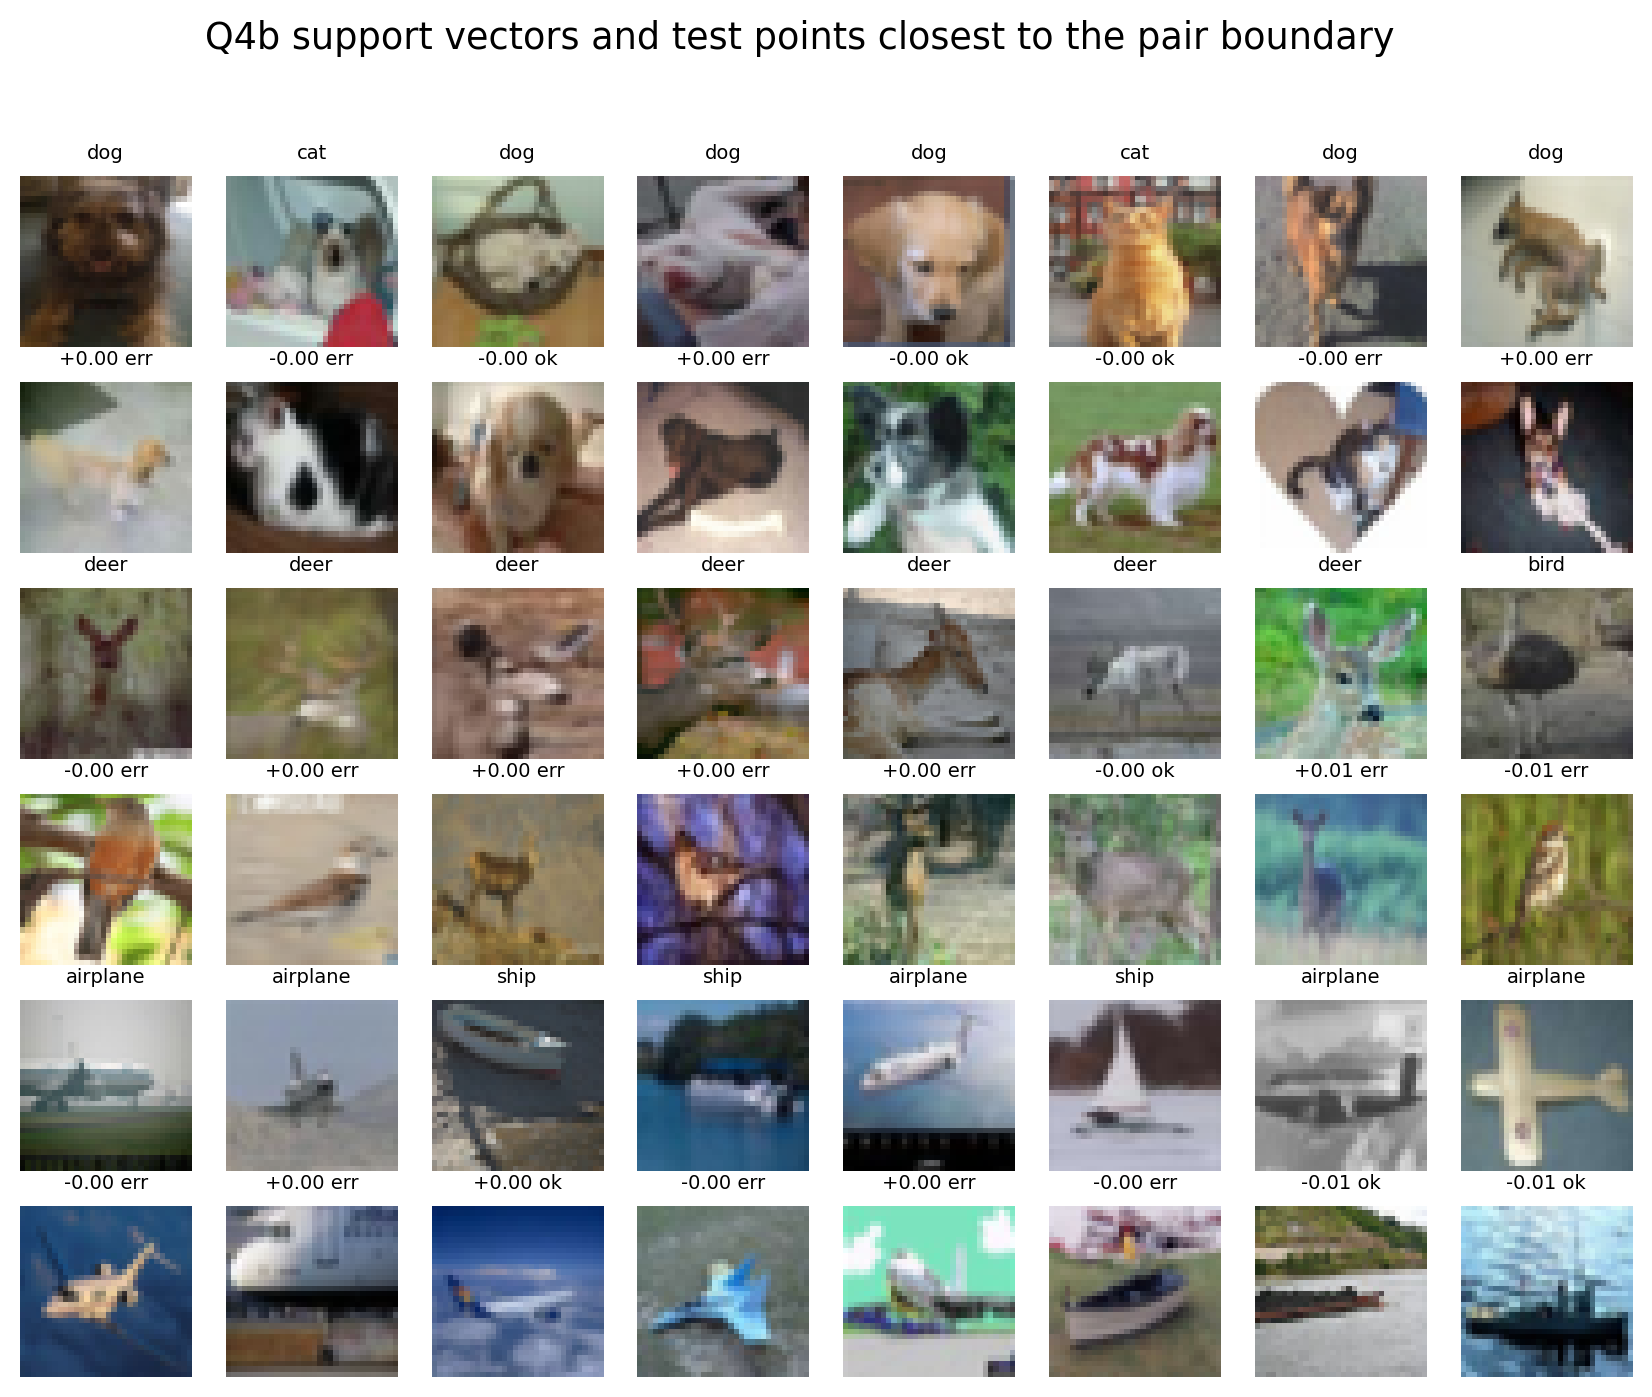

In [6]:
pairs = json.loads((ROOT / "results" / "q4" / "hard_pairs.json").read_text())["pairs"]
show_rows([
    {
        "pair": f"{pair['class_i_name']} / {pair['class_j_name']}",
        "test_confusions": pair["test_confusions"],
        "pair_images": pair["test_pair_count"],
        "error_rate": pair["error_rate"],
        "support_vectors": pair["n_support_vectors"],
        "closest_test_score": pair["nearest_test"][0]["decision_score"],
        "closest_correct": pair["nearest_test"][0]["correct"],
    }
    for pair in pairs
])
show_figure("figures/q4/q4_hard_pairs.png", width=820)

## 8. Question 4c — clustering without labels

KMeans is fit on the same 2,000 standardised training features. Labels are not passed to the fitter. The number of clusters is chosen by validation NMI, over \(k \in \{5, 8, 10, 12, 15, 20\}\). A tie keeps the \(k\) closer to 10, then the smaller \(k\). Test points are assigned by that model. Test labels are used only afterwards, for ARI, NMI, the contingency table, and the majority-vote accuracy.

The majority map from cluster id to class is fit on the training subset only. The disagreement class is the one with the largest SVM recall minus that cluster recall.

k,validation_nmi,validation_ari
5,0.3574,0.2491
8,0.3511,0.2365
10,0.3622,0.2261
12,0.3542,0.2113
15,0.3571,0.2141
20,0.3525,0.1830


chosen k: 10
test ARI: 0.2284346764703447
test NMI: 0.3613777984805836
cluster majority accuracy: 0.4604
SVM test accuracy: 0.7235


class,svm_recall,cluster_recall,svm_minus_cluster
airplane,0.7660,0.6440,0.1220
automobile,0.8520,0.4170,0.4350
bird,0.6150,0.0000,0.6150
cat,0.5360,0.5550,-0.0190
deer,0.6890,0.4190,0.2700
dog,0.6420,0.4010,0.2410
frog,0.7570,0.6050,0.1520
horse,0.7420,0.5180,0.2240
ship,0.8340,0.4170,0.4170
truck,0.8020,0.6280,0.1740


disagreement class: bird SVM recall 0.615 cluster recall 0.0


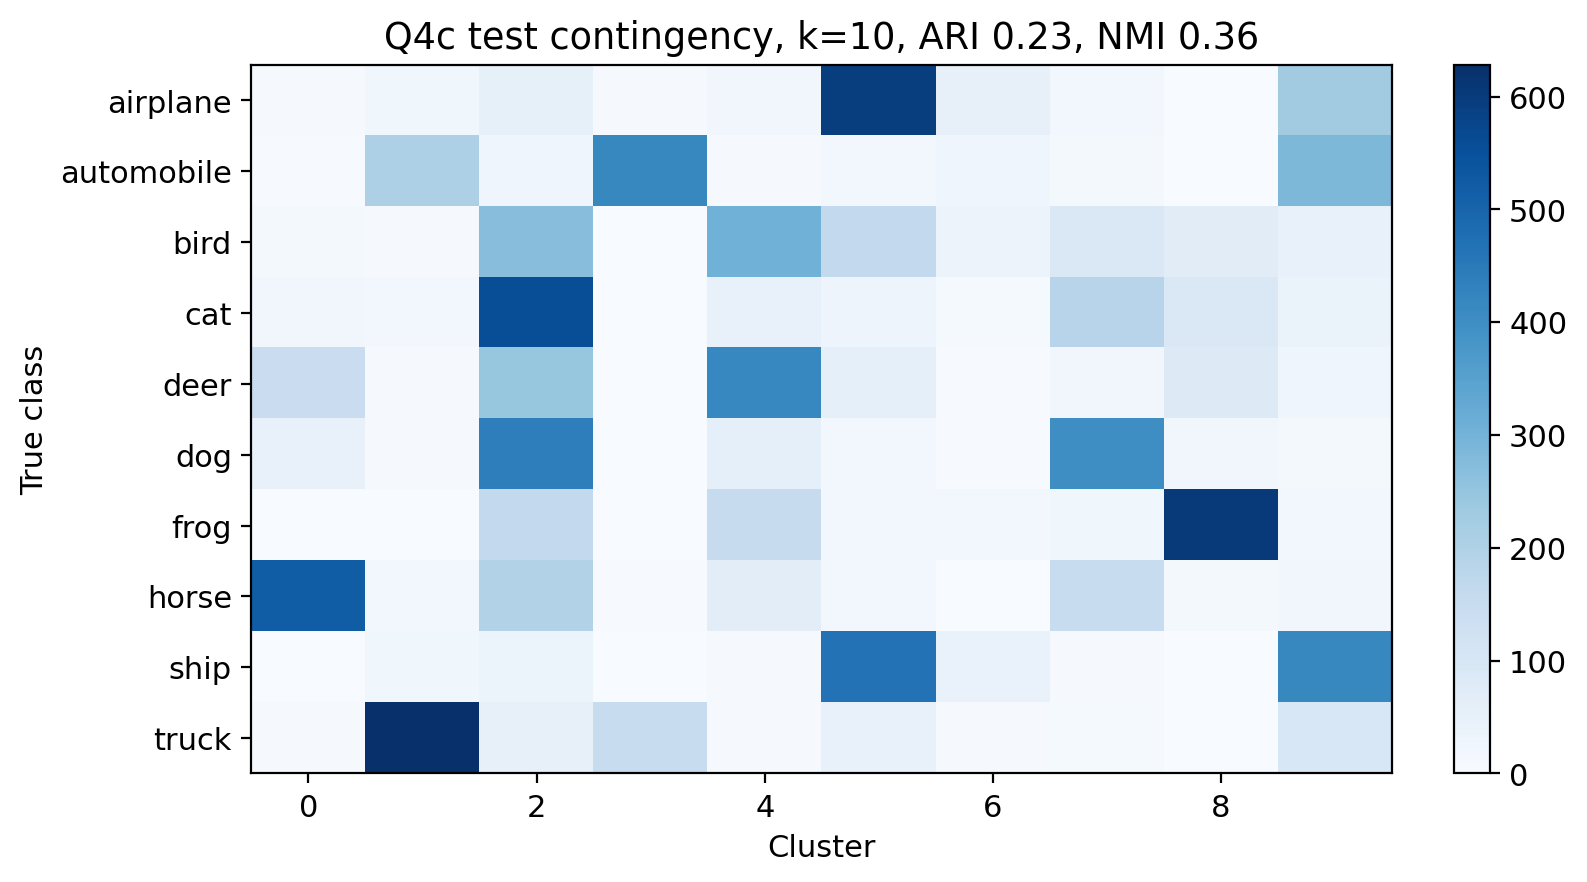

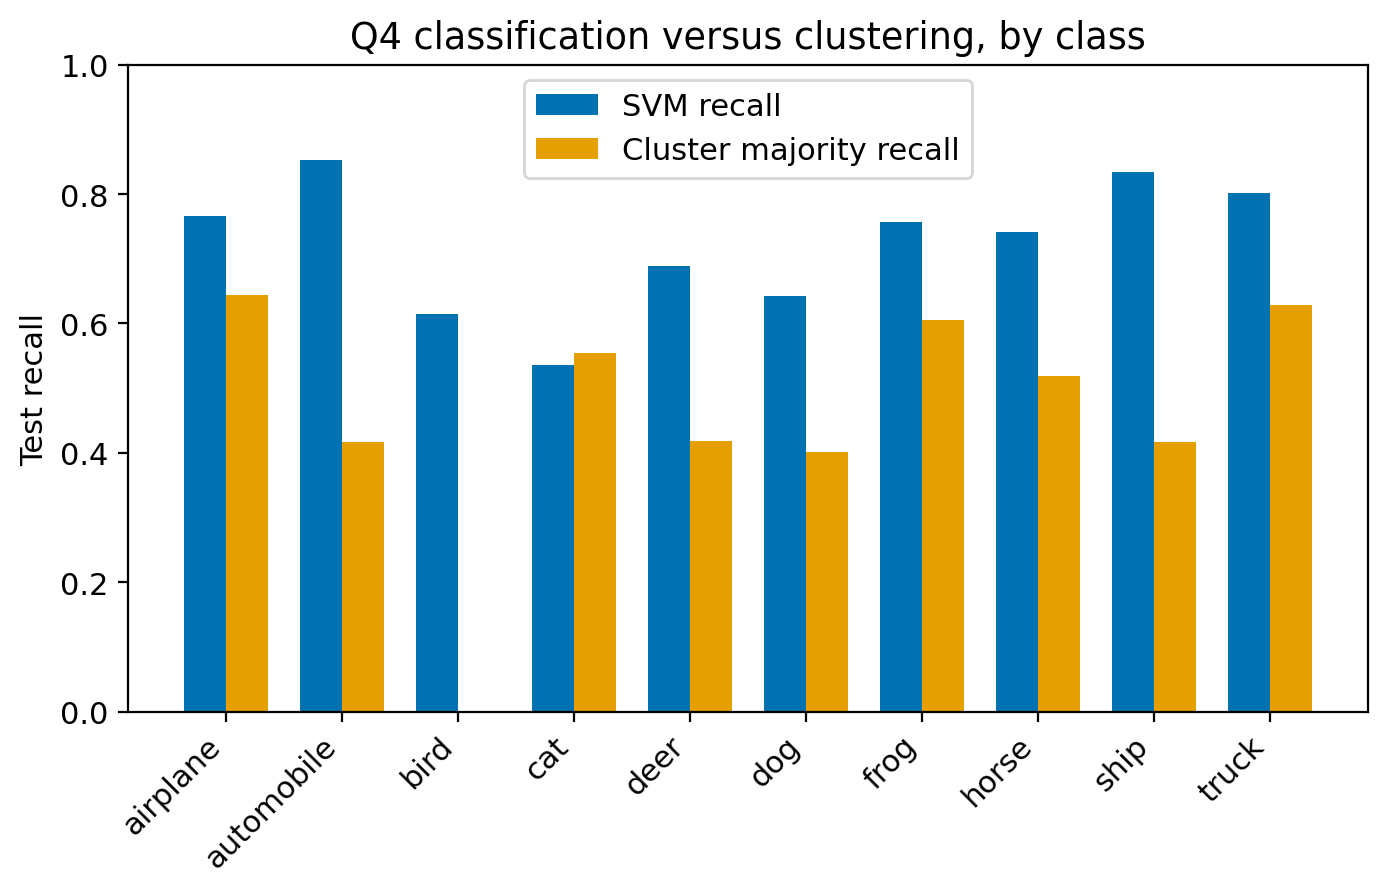

In [7]:
clustering = json.loads((ROOT / "results" / "q4" / "clustering.json").read_text())
show_rows([
    {"k": row["k"], "validation_nmi": row["val_nmi"], "validation_ari": row["val_ari"]}
    for row in clustering["k_rows"]
])
print("chosen k:", clustering["chosen_k"])
print("test ARI:", clustering["test_ari"])
print("test NMI:", clustering["test_nmi"])
print("cluster majority accuracy:", clustering["test_majority_accuracy"])
print("SVM test accuracy:", clustering["svm_test_accuracy"])
show_rows([
    {
        "class": row["class_name"],
        "svm_recall": row["svm_recall"],
        "cluster_recall": row["cluster_recall"],
        "svm_minus_cluster": row["svm_minus_cluster"],
    }
    for row in clustering["per_class"]
])
gap = clustering["disagreement_class"]
print(
    "disagreement class:", gap["class_name"],
    "SVM recall", gap["svm_recall"],
    "cluster recall", gap["cluster_recall"],
)
show_figure("figures/q4/q4_contingency.png")
show_figure("figures/q4/q4_recall_comparison.png")

### Reading of Question 4

Polynomial degree 3 with \(C = 1\) wins validation at 0.734, with training accuracy 0.999 and 68.6% of the 2,000 rows as support vectors. The one test accuracy is 0.7235.

Small \(C\) underfits. RBF at \(C = 0.01\) has training accuracy 0.693, validation 0.609, and every training point is a support vector. Linear overfits as \(C\) grows: validation is 0.730 at \(C = 0.01\) and about 0.710 once training accuracy has reached 1. Polynomial and RBF are unchanged from \(C = 10\) to \(C = 100\).

The hardest test pairs are cat/dog (358 confusions, error rate 0.179), bird/deer (178, 0.089) and airplane/ship (146, 0.073). The cat/dog test image closest to the boundary is an error, with a decision score near zero.

KMeans with \(k = 10\) has validation NMI 0.362. Test ARI is 0.228, test NMI is 0.361, and majority-vote accuracy is 0.460, against the SVM's 0.724. Bird is the disagreement class: SVM recall 0.615, and no training cluster has bird as its majority label, so the cluster map's bird recall is 0.

## 9. Summary of Part 2

A wider bottleneck reconstructs better and is easier for a linear probe to read, but the two gains are not proportional. Denoising improves pixel error relative to a clean autoencoder and does not improve the frozen CNN's accuracy on those reconstructions. On the frozen convolutional features, a polynomial SVM selected only on validation reaches 0.724 test accuracy, while label-free KMeans on the same vectors reaches 0.460 by a training-set majority map and does not recover the bird class.

In [8]:
if RECOMPUTE:
    from src.q3.pipeline import main as train_q3
    from src.q4.pipeline import main as train_q4
    train_q3()
    train_q4()
else:
    print("Using the saved Question 3 and Question 4 logs. Retraining is scripts/q234_srun.sh on a GPU node.")

Using the saved Question 3 and Question 4 logs. Retraining is scripts/q234_srun.sh on a GPU node.
